In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import warnings
warnings.filterwarnings("ignore")


In [3]:
# Загрузка данных из Excel файла
df = pd.read_excel('data.xlsx', 
                   sheet_name='ВТР 2021',
                   usecols=['RESP', 'GOD', 'MES', 'OKRYG_SV', 'NASOBRAZ', 
                           'FOR_ZAC', 'NAS_VOZR', 'BZ_DOX', 'TRUD_RB5', 'DPS_RB5'])




In [4]:
df.head()

,RESP,GOD,MES,OKRYG_SV,NAS_VOZR,NASOBRAZ,FOR_ZAC,TRUD_RB5,DPS_RB5,BZ_DOX
0,1219,2021,9,7,33,3,1,0.0,7.0,0
1,2217,2021,7,7,21,3,0,0.0,0.0,0
2,10214,2021,4,7,22,4,1,0.0,0.0,1
3,12215,2021,5,7,21,3,1,0.0,0.0,2
4,15214,2021,4,7,25,9,1,0.0,0.0,2


In [17]:
# Создаем словарь для перекодировки значений
okrug_mapping = {
    1: 'Центральный ФО',
    2: 'Северо-Западный ФО',
    3: 'Южный ФО',
    4: 'Северо-Кавказский ФО',
    5: 'Приволжский ФО',
    6: 'Уральский ФО',
    7: 'Сибирский ФО',
    8: 'Дальневосточный ФО'
}

# Применяем перекодировку
df['OKRYG_SV'] = df['OKRYG_SV'].replace(okrug_mapping)

# Создаем словарь для перекодировки значений образования
education_mapping = {
    1: 'Высшее - специалитет/магистратура',
    3: 'СПО - специалисты среднего звена',
    4: 'СПО - квалифицированные рабочие',
    8: 'Послевузовское профессиональное',
    9: 'Высшее - бакалавриат'
}

# Применяем перекодировку
df['NASOBRAZ'] = df['NASOBRAZ'].replace(education_mapping)

# Создаем словарь для перекодировки форм обучения
education_form_mapping = {
    1: 'Очная',
    2: 'Очно-заочная',
    3: 'Заочная'
}

# Применяем перекодировку
df['FOR_ZAC'] = df['FOR_ZAC'].replace(education_form_mapping)

# Создаем словарь для перекодировки форм обучения
work_experience_mapping = {
    1: 'Имеют опыт',
    2: 'Не имеют опыта'
}

# Применяем перекодировку
df['BZ_DOX'] = df['BZ_DOX'].replace(work_experience_mapping)

In [6]:
# Проверка размерности датафрейма
print("\nРазмер датафрейма:", df.shape)

# Проверка типов данных
print("\nТипы данных в колонках:")
print(df.dtypes)

# Проверка на наличие пропущенных значений
print("\nКоличество пропущенных значений:")
print(df.isnull().sum())


Размер датафрейма: (21526, 10)

Типы данных в колонках:
RESP          int64
GOD           int64
MES           int64
OKRYG_SV     object
NAS_VOZR      int64
NASOBRAZ     object
FOR_ZAC      object
TRUD_RB5    float64
DPS_RB5     float64
BZ_DOX        int64
dtype: object

Количество пропущенных значений:
RESP        0
GOD         0
MES         0
OKRYG_SV    0
NAS_VOZR    0
NASOBRAZ    0
FOR_ZAC     0
TRUD_RB5    0
DPS_RB5     0
BZ_DOX      0
dtype: int64


Описательная статистика для возраста:
count    21526.000000
mean        25.592679
std          5.418172
min         18.000000
25%         22.000000
50%         24.000000
75%         27.000000
max         65.000000
Name: NAS_VOZR, dtype: float64

Тип переменной: int64
Количество уникальных значений: 47


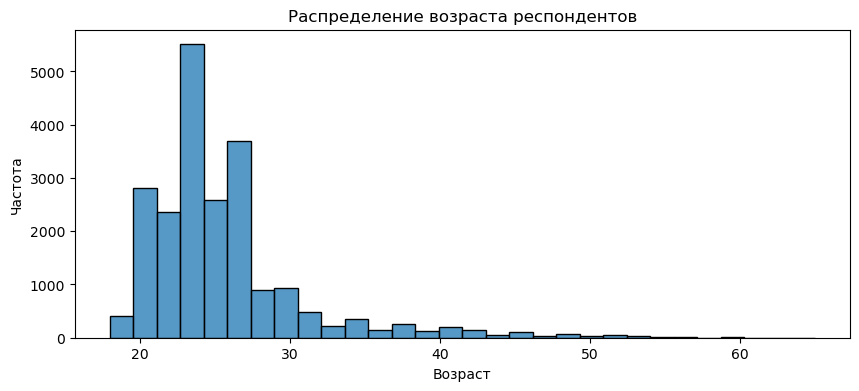

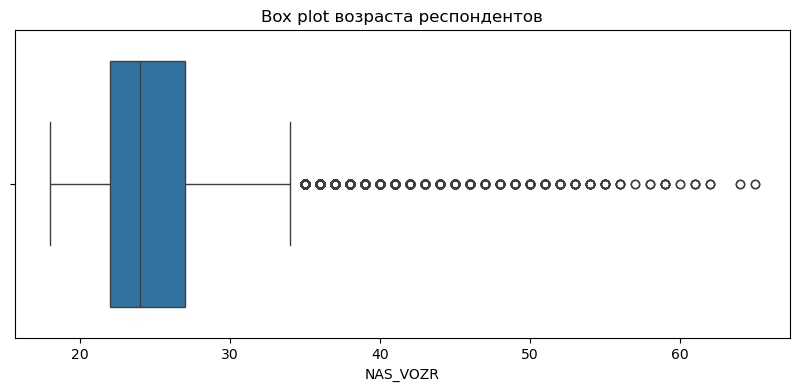


Показатели вариации:
Размах вариации: 47
Интерквартильный размах: 5.0
Коэффициент вариации: 21.17%

Показатели формы распределения:
Коэффициент асимметрии: 2.40
Коэффициент эксцесса: 7.64

Тест на нормальность распределения:
p-value: 0.0
Распределение значимо отличается от нормального


In [20]:
feature = 'NAS_VOZR'


# Базовое описание переменной
print("Описательная статистика для возраста:")
print(df[feature].describe())

# Определение типа переменной
print("\nТип переменной:", df[feature].dtype)
print("Количество уникальных значений:", df[feature].nunique())

# Графический анализ
plt.figure(figsize=(10, 4))
sns.histplot(data=df, x=feature, bins=30)
plt.title('Распределение возраста респондентов')
plt.xlabel('Возраст')
plt.ylabel('Частота')
plt.show()

# Box plot для выявления выбросов
plt.figure(figsize=(10, 4))
sns.boxplot(x=df[feature])
plt.title('Box plot возраста респондентов')
plt.show()

# Расчет показателей вариации
range_var = df[feature].max() - df[feature].min()
q75, q25 = np.percentile(df[feature], [75, 25])
iqr = q75 - q25
cv = (df[feature].std() / df[feature].mean()) * 100

print("\nПоказатели вариации:")
print(f"Размах вариации: {range_var}")
print(f"Интерквартильный размах: {iqr}")
print(f"Коэффициент вариации: {cv:.2f}%")

# Анализ формы распределения
skewness = df[feature].skew()
kurtosis = df[feature].kurtosis()

print("\nПоказатели формы распределения:")
print(f"Коэффициент асимметрии: {skewness:.2f}")
print(f"Коэффициент эксцесса: {kurtosis:.2f}")

# Проверка на нормальность распределения
stat, p_value = stats.normaltest(df[feature])
print("\nТест на нормальность распределения:")
print(f"p-value: {p_value}")
if p_value < 0.05:
    print("Распределение значимо отличается от нормального")
else:
    print("Распределение можно считать нормальным")

Описательная статистика для времени поиска работы:
count    21526.000000
mean         2.463927
std          5.689707
min          0.000000
25%          0.000000
50%          0.500000
75%          2.000000
max         60.000000
Name: DPS_RB5, dtype: float64

Тип переменной: float64
Количество уникальных значений: 18


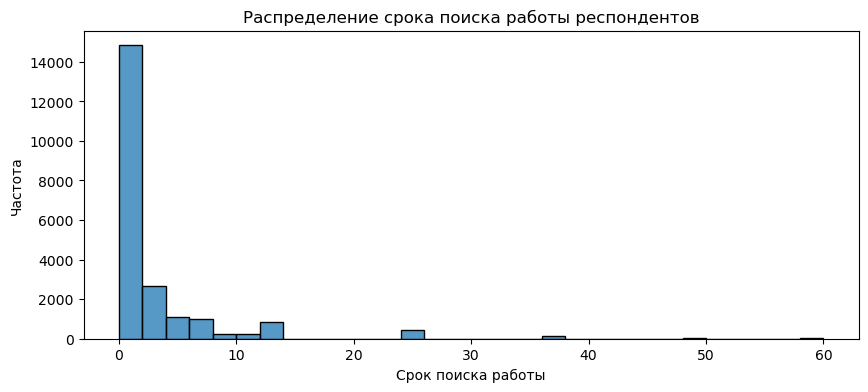

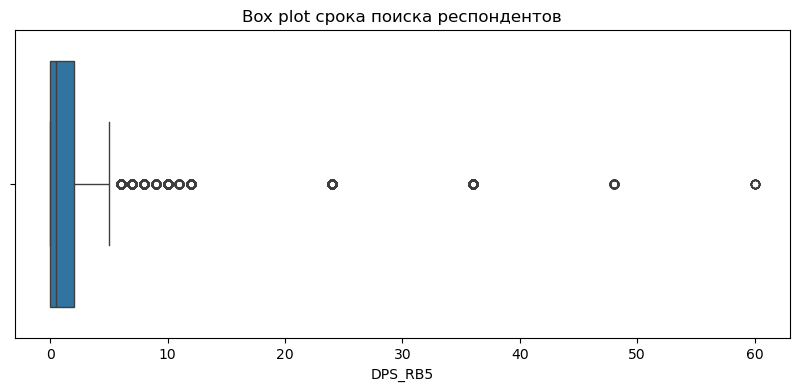


Показатели вариации:
Размах вариации: 60.0
Интерквартильный размах: 2.0
Коэффициент вариации: 230.92%

Показатели формы распределения:
Коэффициент асимметрии: 4.32
Коэффициент эксцесса: 23.87

Тест на нормальность распределения:
p-value: 0.0
Распределение значимо отличается от нормального


In [21]:
feature = 'DPS_RB5'


# Базовое описание переменной
print("Описательная статистика для времени поиска работы:")
print(df[feature].describe())

# Определение типа переменной
print("\nТип переменной:", df[feature].dtype)
print("Количество уникальных значений:", df[feature].nunique())

# Графический анализ
plt.figure(figsize=(10, 4))
sns.histplot(data=df, x=feature, bins=30)
plt.title('Распределение срока поиска работы респондентов')
plt.xlabel('Срок поиска работы')
plt.ylabel('Частота')
plt.show()

# Box plot для выявления выбросов
plt.figure(figsize=(10, 4))
sns.boxplot(x=df[feature])
plt.title('Box plot срока поиска респондентов')
plt.show()

# Расчет показателей вариации
range_var = df[feature].max() - df[feature].min()
q75, q25 = np.percentile(df[feature], [75, 25])
iqr = q75 - q25
cv = (df[feature].std() / df[feature].mean()) * 100

print("\nПоказатели вариации:")
print(f"Размах вариации: {range_var}")
print(f"Интерквартильный размах: {iqr}")
print(f"Коэффициент вариации: {cv:.2f}%")

# Анализ формы распределения
skewness = df[feature].skew()
kurtosis = df[feature].kurtosis()

print("\nПоказатели формы распределения:")
print(f"Коэффициент асимметрии: {skewness:.2f}")
print(f"Коэффициент эксцесса: {kurtosis:.2f}")

# Проверка на нормальность распределения
stat, p_value = stats.normaltest(df[feature])
print("\nТест на нормальность распределения:")
print(f"p-value: {p_value}")
if p_value < 0.05:
    print("Распределение значимо отличается от нормального")
else:
    print("Распределение можно считать нормальным")

In [35]:
# Функция для расчета эмпирического корреляционного отношения
def correlation_ratio(categories, values):
    """
    Расчет корреляционного отношения между категориальной и количественной переменными
    """
    categories = np.array(categories)
    values = np.array(values)
    

    
    # Расчет средних значений по группам
    unique_categories = np.unique(categories)
    group_means = np.array([values[categories == cat].mean() for cat in unique_categories])
    
    # Общее среднее
    overall_mean = values.mean()
    
    # Межгрупповая дисперсия
    n = len(values)
    numerator = sum(len(values[categories == cat]) * (mean - overall_mean) ** 2 
                   for cat, mean in zip(unique_categories, group_means))
    
    # Общая дисперсия
    denominator = sum((values - overall_mean) ** 2)
    
    # Корреляционное отношение
    correlation_ratio = np.sqrt(numerator / denominator)
    
    return correlation_ratio

Анализ взаимосвязи:
Эмпирическое корреляционное отношение: 0.072
Эмпирический коэффициент детерминации: 0.005
Сила связи по шкале Чеддока: слабая

Статистика по возрастным группам:
          DPS_RB5             NAS_VOZR      
            count  mean   std     mean   std
age_group                                   
18-25       13659  2.46  5.41    22.79  1.68
26-35        6549  2.78  6.41    28.08  2.41
36-45         992  1.09  4.29    39.67  2.74
46+           326  0.65  4.08    50.24  3.97


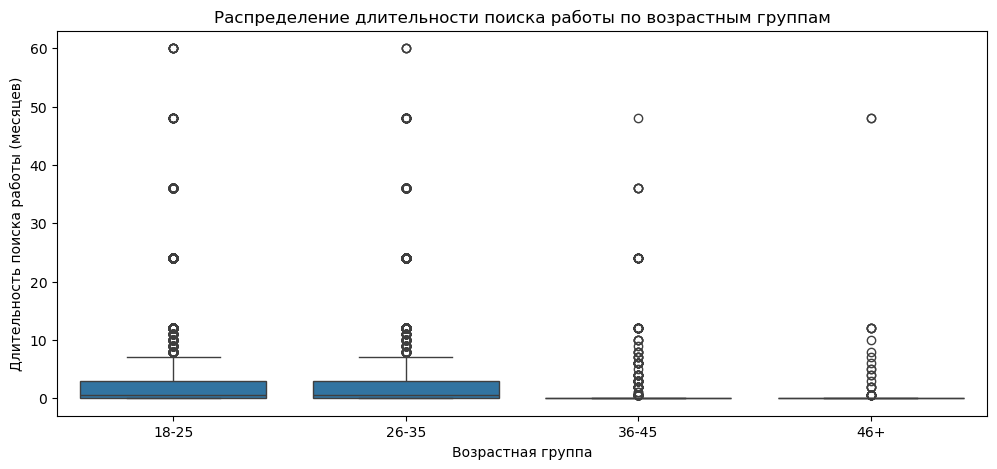

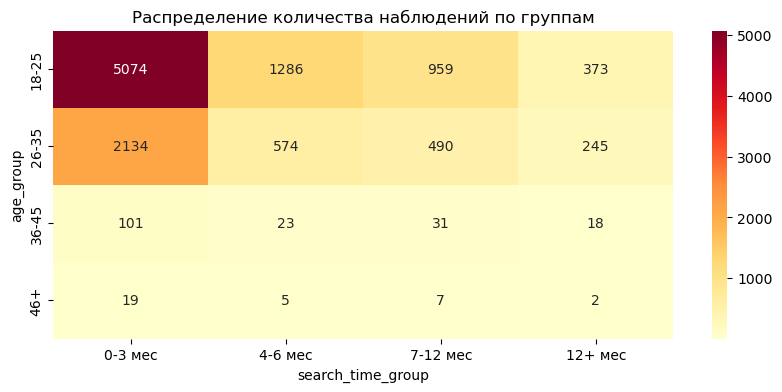


Проверка статистической значимости различий между группами:
F-статистика: 37.091
p-value: 0.000


In [36]:


# Создание возрастных групп
df['age_group'] = pd.cut(df['NAS_VOZR'], 
                        bins=[0, 25, 35, 45, 100],
                        labels=['18-25', '26-35', '36-45', '46+'])

# Создание групп по продолжительности поиска работы
df['search_time_group'] = pd.cut(df['DPS_RB5'],
                                bins=[0, 3, 6, 12, float('inf')],
                                labels=['0-3 мес', '4-6 мес', '7-12 мес', '12+ мес'])

# Расчет корреляционного отношения
correlation = correlation_ratio(df['age_group'].cat.codes, df['DPS_RB5'].fillna(df['DPS_RB5'].mean()))
determination = correlation ** 2

print("Анализ взаимосвязи:")
print(f"Эмпирическое корреляционное отношение: {correlation:.3f}")
print(f"Эмпирический коэффициент детерминации: {determination:.3f}")

# Интерпретация по шкале Чеддока
def interpret_correlation(corr):
    if corr < 0.3:
        return "слабая"
    elif corr < 0.5:
        return "умеренная"
    elif corr < 0.7:
        return "заметная"
    elif corr < 0.9:
        return "высокая"
    else:
        return "очень высокая"

print(f"Сила связи по шкале Чеддока: {interpret_correlation(correlation)}")

# Типологическая группировка
print("\nСтатистика по возрастным группам:")
group_stats = df.groupby('age_group').agg({
    'DPS_RB5': ['count', 'mean', 'std'],
    'NAS_VOZR': ['mean', 'std']
}).round(2)
print(group_stats)

# Визуализация
plt.figure(figsize=(12, 5))
sns.boxplot(x='age_group', y='DPS_RB5', data=df)
plt.title('Распределение длительности поиска работы по возрастным группам')
plt.xlabel('Возрастная группа')
plt.ylabel('Длительность поиска работы (месяцев)')
plt.show()

# Создание сводной таблицы
pivot_table = pd.pivot_table(df,
                            values='DPS_RB5',
                            index='age_group',
                            columns='search_time_group',
                            aggfunc='count',
                            fill_value=0)

# Визуализация тепловой карты
plt.figure(figsize=(10, 4))
sns.heatmap(pivot_table, annot=True, fmt='.0f', cmap='YlOrRd')
plt.title('Распределение количества наблюдений по группам')
plt.show()

# Проверка статистической значимости различий между группами
groups = [group['DPS_RB5'].dropna().values for name, group in df.groupby('age_group')]
f_stat, p_val = stats.f_oneway(*groups)

print("\nПроверка статистической значимости различий между группами:")
print(f"F-статистика: {f_stat:.3f}")
print(f"p-value: {p_val:.3f}")



In [41]:
feature = 'FOR_ZAC'

# Дополнительный анализ типологических групп
typological_groups = df.groupby([feature]).agg({
    'DPS_RB5': ['count', 'mean', 'std'],
}).round(2)

print("\nТипологическая группировка:")
print(typological_groups)



Типологическая группировка:
             DPS_RB5            
               count  mean   std
FOR_ZAC                         
0                815  0.00  0.00
Заочная         3344  1.31  4.93
Очная          16661  2.86  5.95
Очно-заочная     706  1.50  4.39


In [40]:
feature = 'NASOBRAZ'

# Дополнительный анализ типологических групп
typological_groups = df.groupby([feature]).agg({
    'DPS_RB5': ['count', 'mean', 'std'],
}).round(2)


print("\nТипологическая группировка:")
print(typological_groups)

# Расчет корреляционного отношения
correlation = correlation_ratio(df[feature], df['DPS_RB5'].fillna(df['DPS_RB5'].mean()))
determination = correlation ** 2

print("Анализ взаимосвязи:")
print(f"Эмпирическое корреляционное отношение: {correlation:.3f}")
print(f"Эмпирический коэффициент детерминации: {determination:.3f}")
print(f"Сила связи по шкале Чеддока: {interpret_correlation(correlation)}")


Типологическая группировка:
                                  DPS_RB5            
                                    count  mean   std
NASOBRAZ                                             
Высшее - бакалавриат                 4389  2.40  5.50
Высшее - специалитет/магистратура    6582  2.41  5.49
Послевузовское профессиональное        91  1.63  4.44
СПО - квалифицированные рабочие      3091  2.64  6.40
СПО - специалисты среднего звена     7373  2.48  5.67
Анализ взаимосвязи:
Эмпирическое корреляционное отношение: 0.017
Эмпирический коэффициент детерминации: 0.000
Сила связи по шкале Чеддока: слабая


In [42]:
feature = 'OKRYG_SV'

# Дополнительный анализ типологических групп
typological_groups = df.groupby([feature]).agg({
    'DPS_RB5': ['count', 'mean', 'std'],
}).round(2)


print("\nТипологическая группировка:")
print(typological_groups)

# Расчет корреляционного отношения
correlation = correlation_ratio(df[feature], df['DPS_RB5'].fillna(df['DPS_RB5'].mean()))
determination = correlation ** 2

print("Анализ взаимосвязи:")
print(f"Эмпирическое корреляционное отношение: {correlation:.3f}")
print(f"Эмпирический коэффициент детерминации: {determination:.3f}")
print(f"Сила связи по шкале Чеддока: {interpret_correlation(correlation)}")


Типологическая группировка:
                     DPS_RB5            
                       count  mean   std
OKRYG_SV                                
Дальневосточный ФО      1988  2.46  6.08
Приволжский ФО          4071  2.36  5.50
Северо-Западный ФО      2360  2.31  5.48
Северо-Кавказский ФО    1501  3.31  7.30
Сибирский ФО            2337  2.66  6.34
Уральский ФО            1523  2.35  5.61
Центральный ФО          5583  2.27  5.01
Южный ФО                2163  2.60  5.54
Анализ взаимосвязи:
Эмпирическое корреляционное отношение: 0.047
Эмпирический коэффициент детерминации: 0.002
Сила связи по шкале Чеддока: слабая


## Дополнительный анализ: сила связи для формы обучения

В исходной версии для  была посчитана только таблица средних, без оценки силы связи.
Ниже — расчёт корреляционного отношения и проверка значимости по Фишеру.

Отдельно: категория  (815 наблюдений) — служебная, у всех записей в ней
 при нулевом разбросе, то есть признак фактически не заполнен.
Она исключается из анализа, иначе искусственно завышает межгрупповую дисперсию.

In [ ]:
feature = 'FOR_ZAC'
target = 'DPS_RB5'

# Проверяем характер служебной категории 0
print('Категория FOR_ZAC = 0:')
print(df[df[feature] == 0][target].describe().round(3))
print()

# Рабочая выборка без служебной категории
df_fz = df[df[feature] != 0].copy()
print(f'Исключено наблюдений: {len(df) - len(df_fz)}  |  осталось: {len(df_fz)}')
print()

# Сила связи
eta = correlation_ratio(df_fz[feature], df_fz[target])
print(f'Эмпирическое корреляционное отношение: {eta:.3f}')
print(f'Эмпирический коэффициент детерминации: {eta**2:.4f}')

def chaddock(e):
    if e < 0.1:  return 'практически отсутствует'
    if e < 0.3:  return 'слабая'
    if e < 0.5:  return 'умеренная'
    if e < 0.7:  return 'заметная'
    if e < 0.9:  return 'высокая'
    return 'весьма высокая'
print(f'Сила связи по шкале Чеддока: {chaddock(eta)}')
print()

# Проверка значимости различий между формами обучения
groups = [g[target].values for _, g in df_fz.groupby(feature)]
F, p = stats.f_oneway(*groups)
print(f'F-статистика: {F:.3f}')
print(f'p-value: {p:.3e}')

## Медианы вместо средних

Коэффициент вариации целевой переменной — 230,9%, асимметрия 4,32, первый квартиль равен нулю:
четверть выпускников трудоустроилась мгновенно. На таком распределении среднее смещено длинным
правым хвостом, поэтому сравнение групп по средним вводит в заблуждение.

Ниже те же группировки с медианой и долей тех, кто нашёл работу сразу.

In [ ]:
target = 'DPS_RB5'

def group_report(col, data=None):
    d = df if data is None else data
    out = d.groupby(col)[target].agg(
        n='count',
        mean='mean',
        median='median',
        q75=lambda x: x.quantile(0.75),
        share_zero=lambda x: (x == 0).mean()
    ).round(3)
    out['share_zero'] = (out['share_zero'] * 100).round(1)
    out = out.rename(columns={'share_zero': 'нашли сразу, %'})
    return out

print('Общая картина по выборке:')
print(f"  медиана: {df[target].median():.2f} мес.")
print(f"  среднее: {df[target].mean():.2f} мес.")
print(f"  доля нашедших работу сразу (0 мес.): {(df[target] == 0).mean() * 100:.1f}%")
print()

for col in ['age_group', 'FOR_ZAC', 'NASOBRAZ', 'OKRYG_SV']:
    data = df[df['FOR_ZAC'] != 0] if col == 'FOR_ZAC' else df
    print(f'--- {col} ---')
    print(group_report(col, data))
    print()

## Наличие трудового опыта (BZ_DOX)

Признак был отобран во введении, но в расчётной части не анализировался. Закрываем пробел.

In [ ]:
feature = 'BZ_DOX'
target = 'DPS_RB5'

print('Распределение по категориям:')
print(df[feature].value_counts().sort_index())
print()

print('Время поиска работы по категориям:')
print(df.groupby(feature)[target].agg(
    n='count', mean='mean', median='median', std='std'
).round(2))
print()

eta = correlation_ratio(df[feature], df[target])
print(f'Эмпирическое корреляционное отношение: {eta:.3f}')
print(f'Эмпирический коэффициент детерминации: {eta**2:.4f}')
print(f'Сила связи по шкале Чеддока: {chaddock(eta)}')

groups = [g[target].values for _, g in df.groupby(feature)]
F, p = stats.f_oneway(*groups)
print(f'F-статистика: {F:.3f}')
print(f'p-value: {p:.3e}')

In [43]:
def analyze_dynamics(df, column_name):
    """
    Функция для анализа динамики показателя
    """
    # Группируем данные по месяцу опроса и считаем среднее значение показателя
    yearly_data = df.groupby('MES')[column_name].mean()
    
    # Расчет темпа роста (в процентах)
    growth_rate = (yearly_data / yearly_data.shift(1) * 100)
    
    # Расчет темпа прироста (в процентах)
    growth_pace = growth_rate - 100
    
    # Создаем DataFrame с результатами
    dynamics_df = pd.DataFrame({
        'Значение': yearly_data,
        'Темп роста, %': growth_rate,
        'Темп прироста, %': growth_pace
    })
    
    # Построение прогноза на следующий месяц
    X = np.arange(len(yearly_data)).reshape(-1, 1)
    y = yearly_data.values
    
    # Линейная регрессия
    model = stats.linregress(X.flatten(), y)
    
    # Прогноз на следующий месяц
    next_month = len(yearly_data)
    forecast = model.slope * next_month + model.intercept
    
    # Визуализация
    plt.figure(figsize=(15, 10))
    
    # График 1: Исходные данные и прогноз
    plt.subplot(2, 1, 1)
    plt.plot(yearly_data.index, yearly_data.values, 'b-', label='Фактические данные')
    plt.plot(yearly_data.index, model.slope * X.flatten() + model.intercept, 'r--', 
             label='Линия тренда')
    plt.plot(10, forecast, 'go', label='Прогноз')
    plt.title(f'Динамика показателя {column_name}')
    plt.xlabel('Месяц')
    plt.ylabel('Значение показателя')
    plt.legend()
    plt.grid(True)
    
    # График 2: Темпы роста и прироста
    plt.subplot(2, 1, 2)
    plt.plot(growth_pace.index, growth_pace.values, 'r-', label='Темп прироста')
    plt.title('Темпы прироста')
    plt.xlabel('Месяц')
    plt.ylabel('Процент')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()
    
    return dynamics_df, forecast

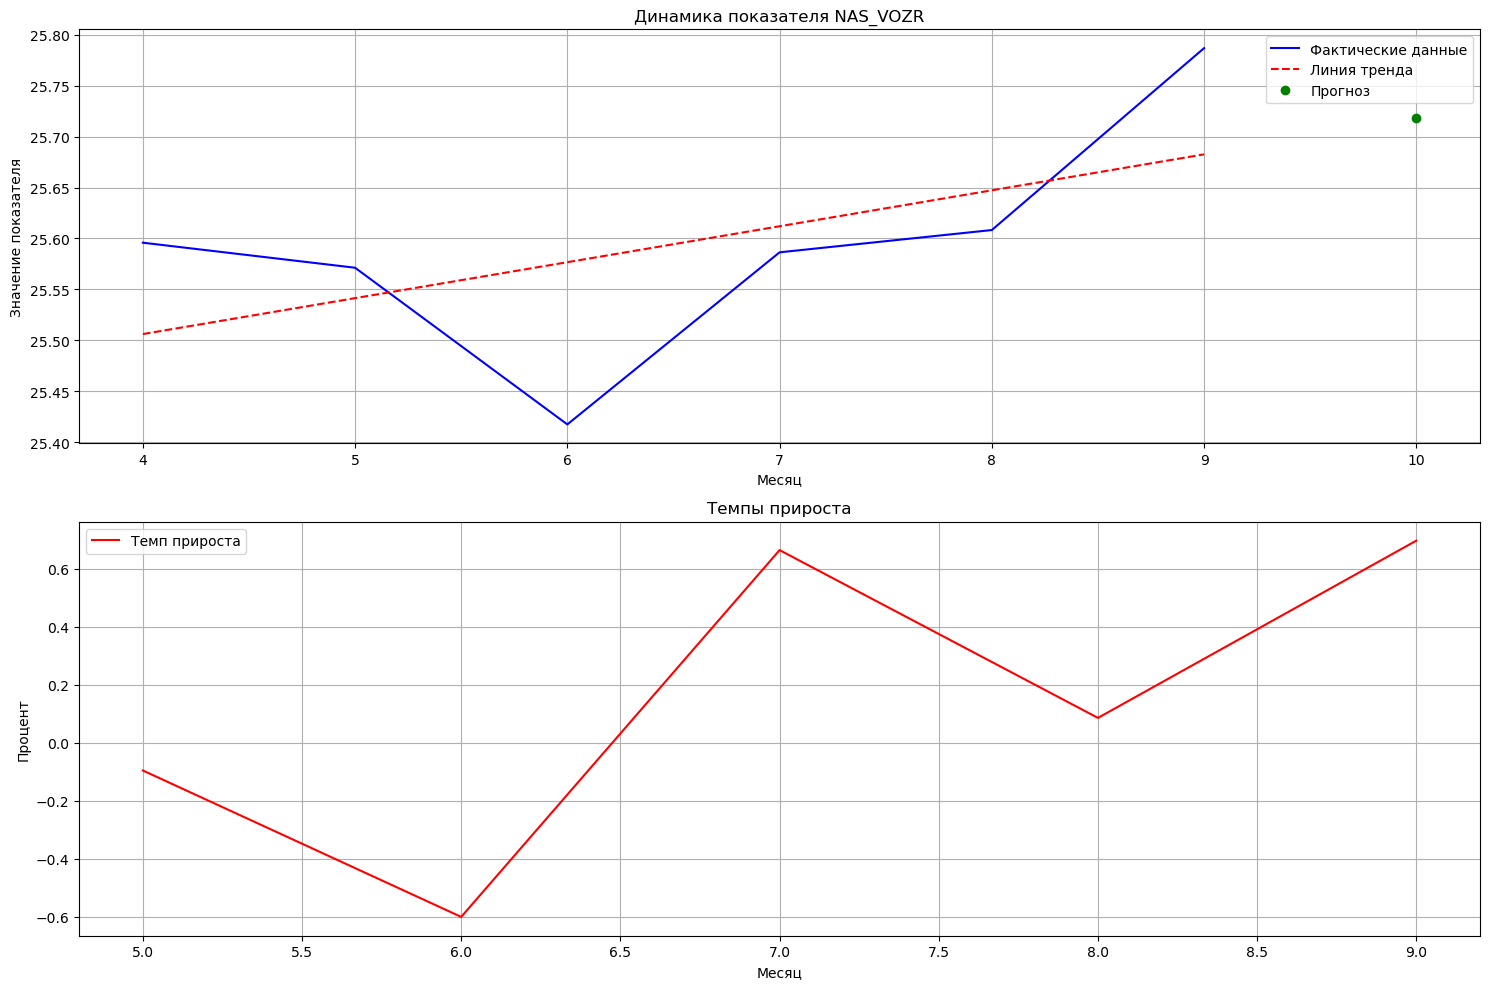


Результаты анализа динамики:
      Значение  Темп роста, %  Темп прироста, %
MES                                            
4    25.595851            NaN               NaN
5    25.571276      99.903989         -0.096011
6    25.417503      99.398649         -0.601351
7    25.586404     100.664507          0.664507
8    25.608268     100.085453          0.085453
9    25.786799     100.697161          0.697161

Прогноз на следующий месяц опроса: 25.72


In [44]:


# Пример использования функции для анализа возраста
dynamics_result, forecast_value = analyze_dynamics(df, 'NAS_VOZR')

# Вывод результатов
print("\nРезультаты анализа динамики:")
print(dynamics_result)
print(f"\nПрогноз на следующий месяц опроса: {forecast_value:.2f}")



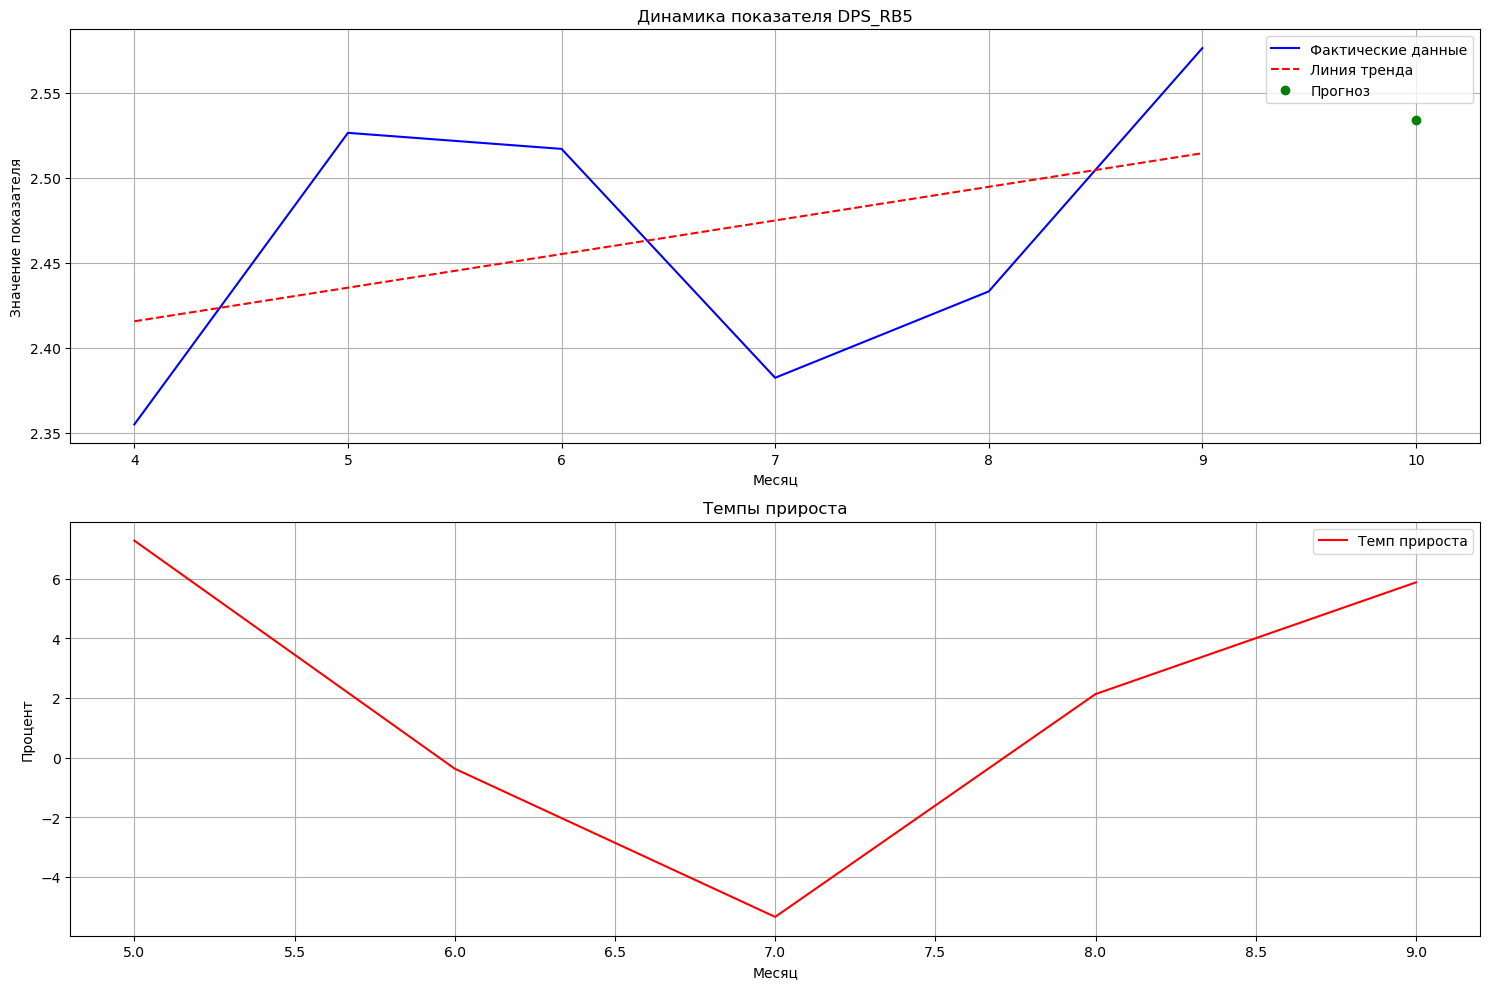


Результаты анализа динамики:
     Значение  Темп роста, %  Темп прироста, %
MES                                           
4    2.354911            NaN               NaN
5    2.526295     107.277728          7.277728
6    2.516862      99.626609         -0.373391
7    2.382319      94.654358         -5.345642
8    2.433073     102.130437          2.130437
9    2.576081     105.877648          5.877648

Прогноз на следующий месяц опроса: 2.53


In [45]:
# Анализ динамики времени поиска работы
dynamics_result, forecast_value = analyze_dynamics(df, 'DPS_RB5')

# Вывод результатов
print("\nРезультаты анализа динамики:")
print(dynamics_result)
print(f"\nПрогноз на следующий месяц опроса: {forecast_value:.2f}")